# Embeddings, attention and scientific evidence

What does an attention calculation compute, and what evidence does a scientific claim still need?

Proposed 2027; calendar dates pending.


# Embeddings, attention and evidence
Predict the array shapes before running. All coordinates and projection matrices are hand-set. This is a fixed numerical operation, not a trained language model.

('red', 'cell', 'moves', 'slowly')
X, Q, K, V: (4, 3) (4, 2) (4, 2) (4, 2)
Hand example: [[0.6697615493266569, 0.3302384506733431]] [[1.3395230986533138, 1.3209538026933725]]


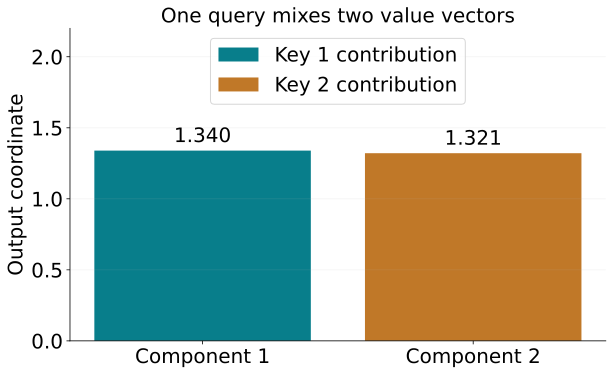

In [1]:
import numpy as np
from demo import run, toy_state, attention, stable_softmax
from IPython.display import SVG, display
results = run()
tokens, X, WQ, WK, WV = toy_state()
Q, K, V = X@WQ, X@WK, X@WV
print(tokens)
print('X, Q, K, V:', X.shape, Q.shape, K.shape, V.shape)
print('Hand example:', results['hand_weights'], results['hand_output'])
display(SVG(filename='weighted-values.svg'))

Interpret the hand example: identify the two contributions and explain why the output is not a vocabulary probability distribution. Next predict which cells of a causal attention matrix must be zero.

Row sums: [1. 1. 1. 1.]


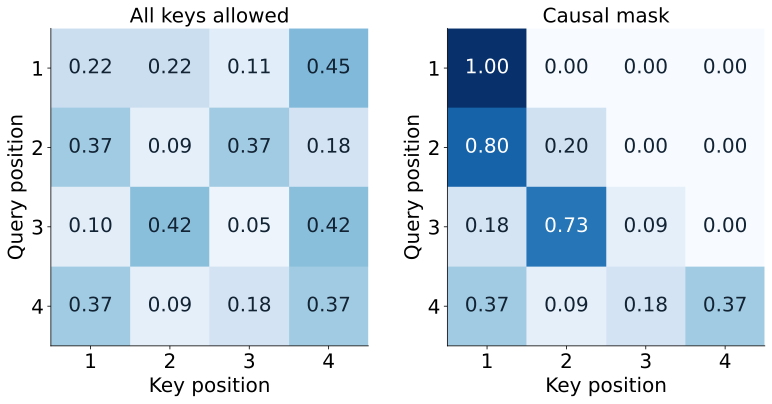

In [2]:
allowed = np.tril(np.ones((len(X),len(X)),dtype=bool))
Z, A, scores = attention(Q,K,V,allowed)
print('Row sums:', A.sum(axis=1))
assert np.all(A[~allowed] == 0)
display(SVG(filename='attention-weights.svg'))

Modify a future row: predict whether outputs at positions 1–3 can change. Keep the coefficients fixed, and test the causal and unmasked cases separately.

In [3]:
changed = X.copy()
changed[-1] = [9,-3,2]
new_Z = attention(changed@WQ,changed@WK,changed@WV,allowed)[0]
assert np.allclose(new_Z[:3],Z[:3])
old_full = attention(Q,K,V)[0]
new_full = attention(changed@WQ,changed@WK,changed@WV)[0]
print('Earlier causal change:', np.max(abs(new_Z[:3]-Z[:3])))
print('Earlier unmasked change:', np.max(abs(new_full[:3]-old_full[:3])))

Earlier causal change: 0.0
Earlier unmasked change: 18.538916083489806


Check numerical behavior: explain why adding the same constant to every score in a row does not change the normalized weights. Predict the output if all value rows are [7,7].

In [4]:
assert np.allclose(stable_softmax([[1000,1001]]),stable_softmax([[0,1]]))
constant = attention(Q,K,np.full_like(V,7),allowed)[0]
print('Constant-value output:', constant)
assert np.allclose(constant,7)

Constant-value output: [[7. 7.]
 [7. 7.]
 [7. 7.]
 [7. 7.]]


Transfer exercise: write a short comparison for the claim that doubling V doubles Z at fixed Q, K and mask. Then explain why no result here establishes which biological process caused a measured observation. Record one independent evidence requirement.